# 2. The Wilson–Cowan pair: phase plane, oscillations, Hopf (Chapters 5–7)
$\dot E = -E + (k_E - E)\mathcal S_E(c_1E - c_2I + P)$, $\dot I = -I + (k_I - I)\mathcal S_I(c_3E - c_4I + Q)$.

**Picture first:** draw both nullclines; their crossings are the steady states; the $E$-nullcline has a hump because of self-excitation.

In [1]:
import numpy as np, matplotlib.pyplot as plt, pyxpp
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.spines.top": False, "axes.spines.right": False})
def load(name, **pars):
    m = pyxpp.load(text=open(f"ode/{name}.ode").read())
    if pars: m.set(**pars)
    return m

In [2]:
def S(x, a, th): return 1/(1+np.exp(-a*(x-th))) - 1/(1+np.exp(a*th))
def Sinv(y, a, th): return th - np.log(1/(y + 1/(1+np.exp(a*th))) - 1)/a
def nullclines(p, e):
    ke = 1 - 1/(1+np.exp(p['ae']*p['the'])); ki = 1 - 1/(1+np.exp(p['ai']*p['thi']))
    IE = (p['c1']*e + p['p'] - Sinv(e/(ke - e), p['ae'], p['the']))/p['c2']
    II = []
    for x in e:
        lo, hi = -0.1, ki - 1e-9
        g = lambda I: (ki - I)*S(p['c3']*x - p['c4']*I + p['q'], p['ai'], p['thi']) - I
        for _ in range(60):
            mid = (lo+hi)/2
            lo, hi = (lo, mid) if g(lo)*g(mid) <= 0 else (mid, hi)
        II.append((lo+hi)/2)
    return IE, np.array(II)
OSC = dict(c1=16, c2=12, c3=15, c4=3, ae=1.3, the=4, ai=2, thi=3.7, p=1.25, q=0)
HYS = dict(c1=12, c2=4, c3=13, c4=11, ae=1.2, the=2.8, ai=1, thi=4, p=0, q=0)

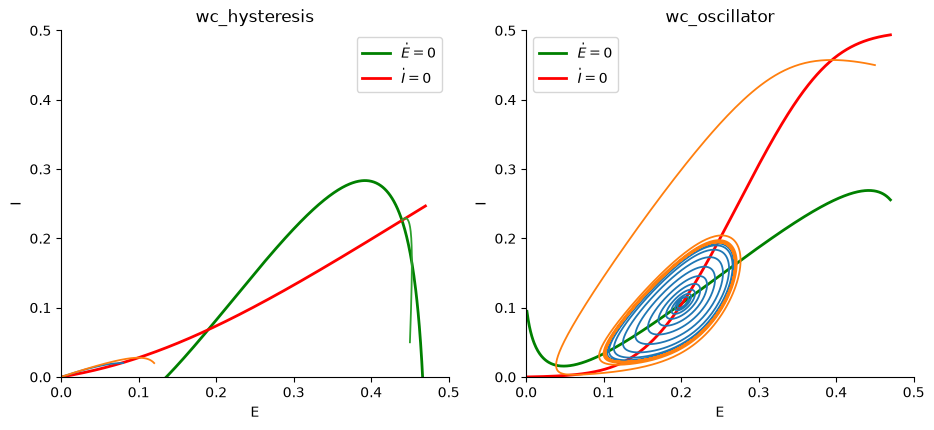

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
e = np.linspace(0.001, 0.47, 600)
for ax, (name, p, starts) in zip(axs, [('wc_hysteresis', HYS, [(0.08, .02), (0.12, .02), (0.45, .05)]),
                                       ('wc_oscillator', OSC, [(0.2, 0.11), (0.45, 0.45)])]):
    IE, II = nullclines(p, e)
    ax.plot(e, IE, 'g', lw=2, label='$\\dot E=0$'); ax.plot(e, II, 'r', lw=2, label='$\\dot I=0$')
    m = load(name)
    for x0 in starts:
        m.set(e=x0[0], i=x0[1]); tr = m.run(total=60)
        ax.plot(tr['e'], tr['i'], lw=1.3)
    ax.set_xlim(0, .5); ax.set_ylim(0, .5); ax.set_xlabel('E'); ax.set_ylabel('I'); ax.set_title(name); ax.legend()

Left: three crossings (rest, saddle, active). Right: one crossing on the rising branch of the hump, so trajectories spiral out onto a limit cycle.

Hopf at P = [1.8793]


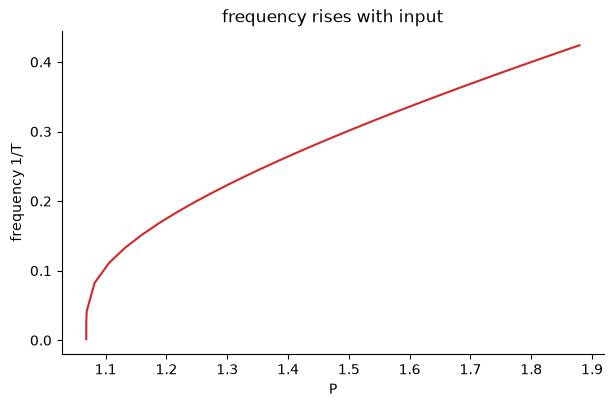

In [4]:
m = load('wc_oscillator'); m.set(p=3.0, e=0.3, i=0.2); m.run(total=200); m.run_last(total=20)
eq = m.auto.run('p', start='steady', ds=-0.02, dsmax=0.05, parmin=1.15, parmax=4.0, nmax=300)
hb = eq.special('HB'); print('Hopf at P =', [round(h.x, 4) for h in hb])
po = m.auto.run(grab=hb[0].label, choice='periodic', ntst=80, dsmax=0.03, nmax=800, parmin=0.9, parmax=4.0)
d = po.to_pandas('e'); d = d[d.period < 1e3]
plt.plot(d.par, 1/d.period, 'C3'); plt.xlabel('P'); plt.ylabel('frequency 1/T'); plt.title('frequency rises with input');

**Try:** in the hysteresis model, ramp `p` from −0.8 to 0.8 and back (as in notebook 1) and find the two folds.